<div align="center">

# **Penerapan Prompt AI untuk Analisis dan Interpretasi Data Geofisika**

<br>

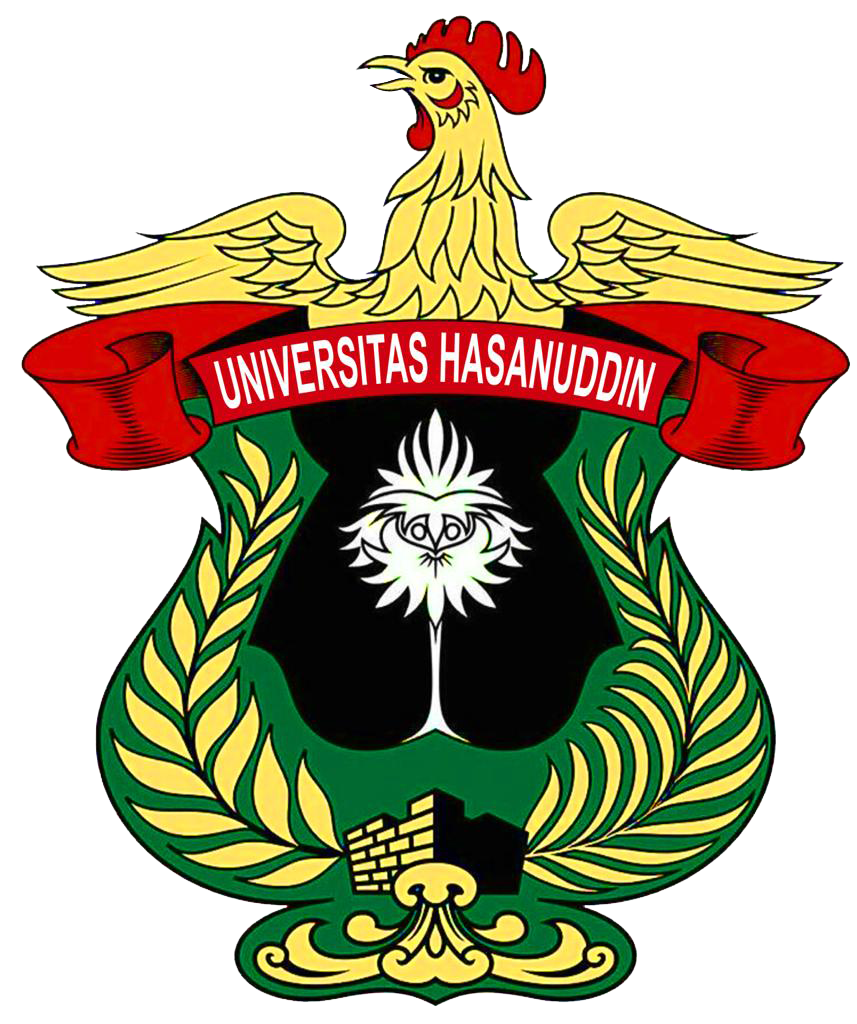

<br>

**TUGAS MATA KULIAH KECERDASAN ARTIFISIAL**  
**SUMBER: AI COOKBOOK UNTUK EARTH SCIENCES**

<br>

**Disusun oleh:**  

**APRILIANDARI**  
**NIM: H061241080**

<br>

**PROGRAM STUDI GEOFISIKA**  
**FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**  
**UNIVERSITAS HASANUDDIN**

<br>

**MAKASSAR**  
**2026**

</div>

# **ANALISIS DATA SEISMIK**

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18312\2244231484.py:216: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


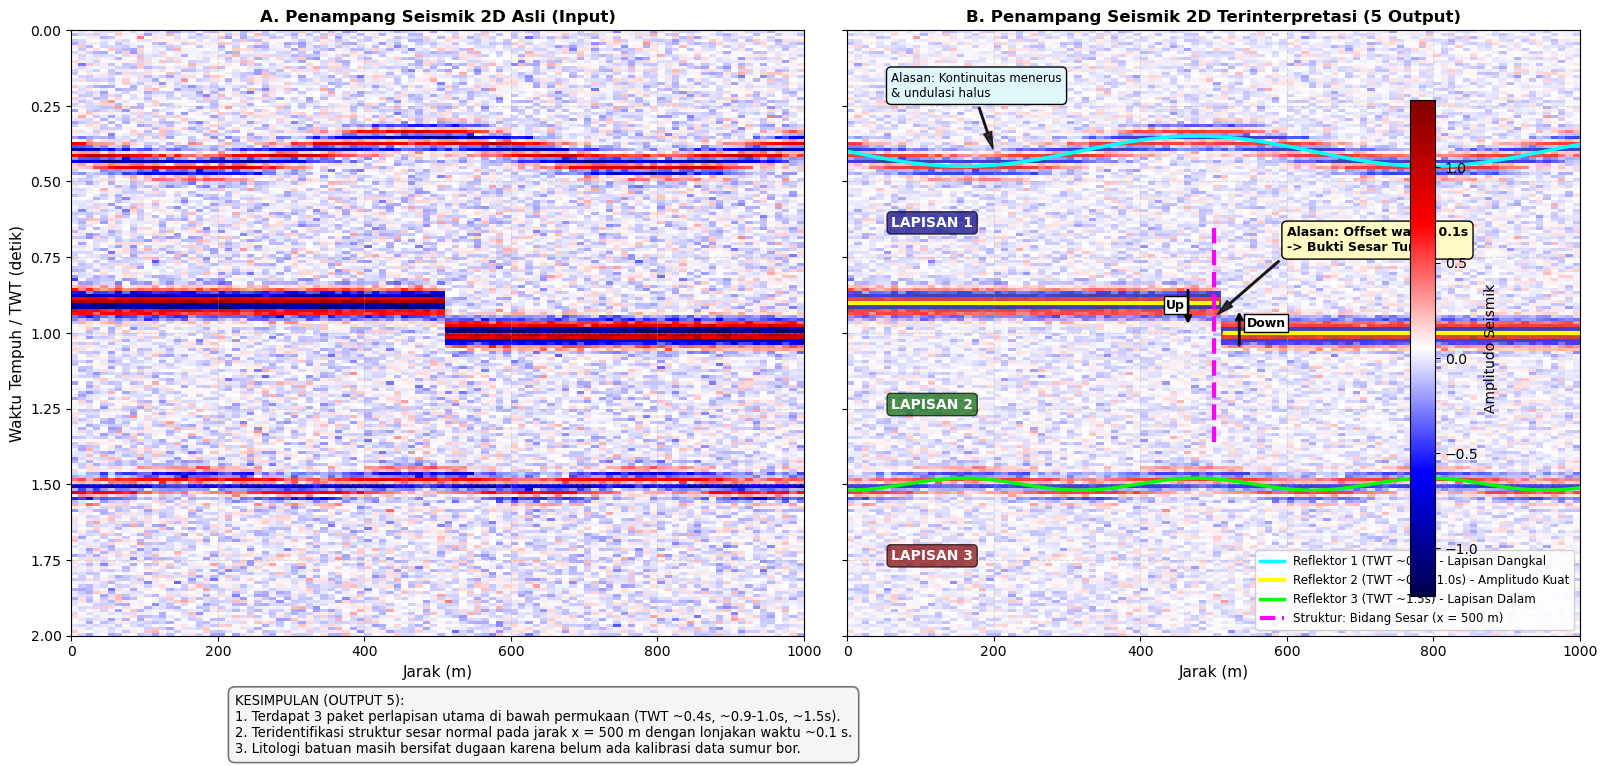

HASIL INTERPRETASI ANALISIS DATA SEISMIK 2D

1. REFLEKTOR UTAMA:
   - Reflektor 1 (TWT ~0.4 s): Bergelombang halus, menerus, amplitudo sedang.
   - Reflektor 2 (TWT ~0.9 - 1.0 s): Amplitudo sangat kuat, terpotong di tengah.
   - Reflektor 3 (TWT ~1.5 s): Sub-horizontal, menerus, amplitudo rendah-sedang.

2. BATAS LAPISAN:
   - Batas Lapisan 1: Membatasi zona permukaan dangkal dengan lapisan di bawahnya.
   - Batas Lapisan 2: Bidang batas dengan kontras impedansi akustik yang tinggi.
   - Batas Lapisan 3: Batas formasi yang lebih dalam.

3. KEMUNGKINAN STRUKTUR GEOLOGI:
   - Struktur Sesar / Patahan pada x ≈ 500 m (sesar turun / normal fault).
   - Deformasi lipatan lemah / undulasi pada lapisan dangkal.

4. ALASAN HASIL INTERPRETASI:
   - Reflektor 2 memiliki amplitudo kuat karena perbedaan sifat fisik lapisan yang tajam.
   - Bidang sesar ditentukan karena adanya pemutusan reflektor mendadak dengan beda waktu 0.1 s.
   - Reflektor 3 tidak menunjukkan offset tegas, sehingga sesar kemun

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP & REKONSTRUKSI DATA SEISMIK 2D (INPUT DATA)
# ==============================================================================
np.random.seed(42)
nx, nt = 100, 200
distance = np.linspace(0, 1000, nx)  # Jarak horizontal (0 - 1000 meter)
twt = np.linspace(0, 2.0, nt)  # Two-Way Travel Time (0 - 2.0 detik)
seismic_data = np.zeros((nt, nx))

# Horizon teoritis untuk pelacakan reflektor
t1_trace = np.zeros(nx)
t2_trace = np.zeros(nx)
t3_trace = np.zeros(nx)

for i in range(nx):
  t1 = 0.4 + 0.05 * np.sin(i / 10)
  t2 = 0.9 + (0.1 if i > 50 else 0.0)
  t3 = 1.5 + 0.02 * np.cos(i / 5)

  t1_trace[i] = t1
  t2_trace[i] = t2
  t3_trace[i] = t3

  seismic_data[:, i] += np.exp(-((twt - t1) ** 2) / 0.002) * np.sin(
      2 * np.pi * 25 * twt
  )
  seismic_data[:, i] += (
      np.exp(-((twt - t2) ** 2) / 0.002) * np.sin(2 * np.pi * 25 * twt) * 1.5
  )
  seismic_data[:, i] += (
      np.exp(-((twt - t3) ** 2) / 0.002) * np.sin(2 * np.pi * 25 * twt) * 0.8
  )

# Penambahan noise realistis
seismic_data += np.random.normal(0, 0.1, seismic_data.shape)

# ==============================================================================
# 2. PLOTTING VISUALISASI KE-5 POIN OUTPUT
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

# ----------------- Panel 1: Data Seismik Mentah (Input) -----------------
im1 = ax1.imshow(
    seismic_data, aspect='auto', cmap='seismic', extent=[0, 1000, 2.0, 0]
)
ax1.set_title(
    'A. Penampang Seismik 2D Asli (Input)', fontsize=12, fontweight='bold'
)
ax1.set_xlabel('Jarak (m)', fontsize=11)
ax1.set_ylabel('Waktu Tempuh / TWT (detik)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.4)

# ----------------- Panel 2: Hasil Interpretasi (5 Output) ---------------
im2 = ax2.imshow(
    seismic_data,
    aspect='auto',
    cmap='seismic',
    extent=[0, 1000, 2.0, 0],
    alpha=0.75,
)
ax2.set_title(
    'B. Penampang Seismik 2D Terinterpretasi (5 Output)',
    fontsize=12,
    fontweight='bold',
)
ax2.set_xlabel('Jarak (m)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.4)

# [OUTPUT 1 & 2]: Picking Reflektor Utama & Batas Lapisan
# Reflektor 1: Dangkal
ax2.plot(
    distance,
    t1_trace,
    color='cyan',
    linewidth=2.5,
    label='Reflektor 1 (TWT ~0.4s) - Lapisan Dangkal',
)
# Reflektor 2: Menengah (Diskontinu karena patahan pada x = 500 m)
ax2.plot(
    distance[:51],
    t2_trace[:51],
    color='yellow',
    linewidth=3.0,
    label='Reflektor 2 (TWT ~0.9 - 1.0s) - Amplitudo Kuat',
)
ax2.plot(distance[51:], t2_trace[51:], color='yellow', linewidth=3.0)
# Reflektor 3: Dalam
ax2.plot(
    distance,
    t3_trace,
    color='lime',
    linewidth=2.5,
    label='Reflektor 3 (TWT ~1.5s) - Lapisan Dalam',
)

# Label Zona Lapisan
ax2.text(
    60,
    0.65,
    'LAPISAN 1',
    fontsize=10,
    fontweight='bold',
    color='white',
    bbox=dict(boxstyle='round,pad=0.3', fc='navy', alpha=0.7),
)
ax2.text(
    60,
    1.25,
    'LAPISAN 2',
    fontsize=10,
    fontweight='bold',
    color='white',
    bbox=dict(boxstyle='round,pad=0.3', fc='darkgreen', alpha=0.7),
)
ax2.text(
    60,
    1.75,
    'LAPISAN 3',
    fontsize=10,
    fontweight='bold',
    color='white',
    bbox=dict(boxstyle='round,pad=0.3', fc='maroon', alpha=0.7),
)

# [OUTPUT 3]: Struktur Geologi (Patahan / Sesar di x = 500 m)
ax2.axvline(
    x=500,
    ymin=0.32,
    ymax=0.68,
    color='magenta',
    linewidth=3.0,
    linestyle='--',
    label='Struktur: Bidang Sesar (x = 500 m)',
)

# Tanda pergerakan sesar (Blok Barat Relatif Naik / Blok Timur Turun)
ax2.annotate(
    '',
    xy=(465, 0.98),
    xytext=(465, 0.85),
    arrowprops=dict(arrowstyle='->', color='black', lw=2),
)
ax2.annotate(
    '',
    xy=(535, 0.92),
    xytext=(535, 1.05),
    arrowprops=dict(arrowstyle='->', color='black', lw=2),
)
ax2.text(
    435,
    0.92,
    'Up',
    fontweight='bold',
    fontsize=9,
    bbox=dict(boxstyle='square', fc='white', ec='black', pad=0.2),
)
ax2.text(
    545,
    0.98,
    'Down',
    fontweight='bold',
    fontsize=9,
    bbox=dict(boxstyle='square', fc='white', ec='black', pad=0.2),
)

# [OUTPUT 4]: Alasan Sederhana dari Setiap Interpretasi (Callout)
ax2.annotate(
    'Alasan: Offset waktu 0.1s\n-> Bukti Sesar Turun',
    xy=(500, 0.95),
    xytext=(600, 0.73),
    arrowprops=dict(
        facecolor='black', shrink=0.05, width=1.2, headwidth=6, alpha=0.8
    ),
    bbox=dict(boxstyle='round,pad=0.4', fc='#FFF9C4', ec='black', lw=1),
    fontsize=9,
    fontweight='bold',
)

ax2.annotate(
    'Alasan: Kontinuitas menerus\n& undulasi halus',
    xy=(200, 0.4),
    xytext=(60, 0.22),
    arrowprops=dict(
        facecolor='black', shrink=0.05, width=1.2, headwidth=6, alpha=0.8
    ),
    bbox=dict(boxstyle='round,pad=0.4', fc='#E0F7FA', ec='black', lw=1),
    fontsize=8.5,
)

# [OUTPUT 5]: Box Ringkasan Kesimpulan Bawah Permukaan
kesimpulan_box = (
    'KESIMPULAN (OUTPUT 5):\n'
    '1. Terdapat 3 paket perlapisan utama di bawah permukaan (TWT ~0.4s, ~0.9-1.0s, ~1.5s).\n'
    '2. Teridentifikasi struktur sesar normal pada jarak x = 500 m dengan lonjakan waktu ~0.1 s.\n'
    '3. Litologi batuan masih bersifat dugaan karena belum ada kalibrasi data sumur bor.'
)
plt.figtext(
    0.15,
    -0.08,
    kesimpulan_box,
    wrap=True,
    fontsize=9.5,
    bbox=dict(boxstyle='round,pad=0.5', fc='#F5F5F5', ec='#757575', lw=1.2),
)

# Colorbar & Legend
cbar = fig.colorbar(
    im1, ax=[ax1, ax2], orientation='vertical', fraction=0.02, pad=0.03
)
cbar.set_label('Amplitudo Seismik', fontsize=10)
ax2.legend(loc='lower right', fontsize=8.5, framealpha=0.9)

plt.tight_layout()
plt.show()


print('HASIL INTERPRETASI ANALISIS DATA SEISMIK 2D')
print("""
1. REFLEKTOR UTAMA:
   - Reflektor 1 (TWT ~0.4 s): Bergelombang halus, menerus, amplitudo sedang.
   - Reflektor 2 (TWT ~0.9 - 1.0 s): Amplitudo sangat kuat, terpotong di tengah.
   - Reflektor 3 (TWT ~1.5 s): Sub-horizontal, menerus, amplitudo rendah-sedang.

2. BATAS LAPISAN:
   - Batas Lapisan 1: Membatasi zona permukaan dangkal dengan lapisan di bawahnya.
   - Batas Lapisan 2: Bidang batas dengan kontras impedansi akustik yang tinggi.
   - Batas Lapisan 3: Batas formasi yang lebih dalam.

3. KEMUNGKINAN STRUKTUR GEOLOGI:
   - Struktur Sesar / Patahan pada x ≈ 500 m (sesar turun / normal fault).
   - Deformasi lipatan lemah / undulasi pada lapisan dangkal.

4. ALASAN HASIL INTERPRETASI:
   - Reflektor 2 memiliki amplitudo kuat karena perbedaan sifat fisik lapisan yang tajam.
   - Bidang sesar ditentukan karena adanya pemutusan reflektor mendadak dengan beda waktu 0.1 s.
   - Reflektor 3 tidak menunjukkan offset tegas, sehingga sesar kemungkinan tidak tembus sampai dalam.

5. KESIMPULAN KONDISI BAWAH PERMUKAAN:
   Area penelitian terdiri dari tiga lapisan utama dengan aktivitas tektonik lokal
   yang membentuk bidang sesar turun di bagian tengah penampang. Litologi spesifik
   masih berupa dugaan tanpa data pendukung tambahan.
""")


# **INTERPRETASI ANOMALI GRAVITASI**

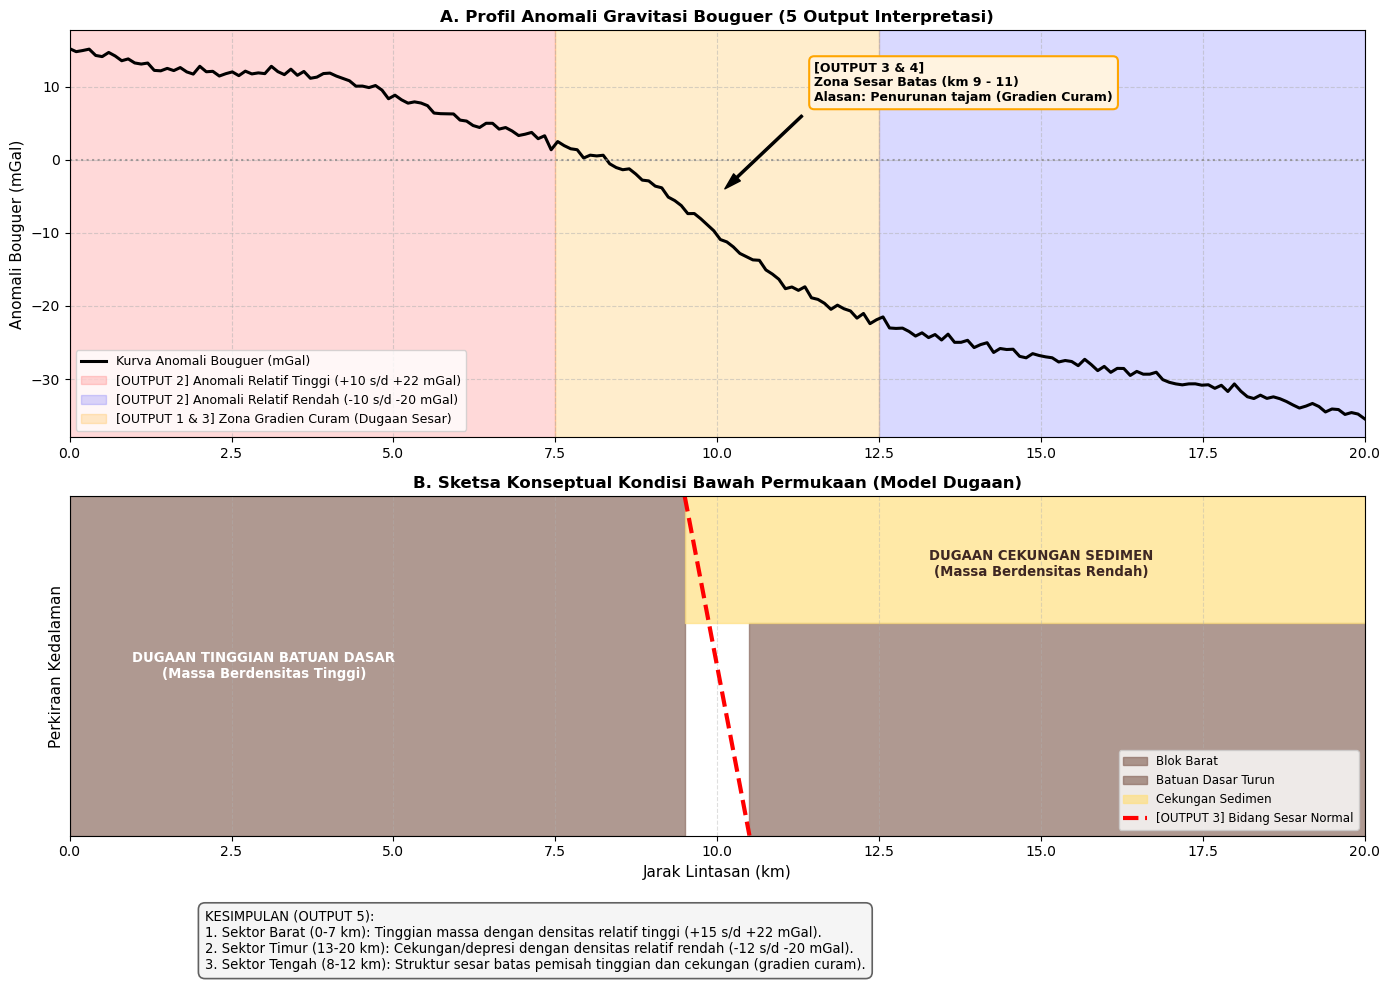

HASIL INTERPRETASI ANOMALI GRAVITASI (5 POIN OUTPUT)

1. POLA ANOMALI GRAVITASI:
   - Pola tinggian mendatar di bagian barat (0 - 7 km).
   - Pola gradien curam (perubahan drastis) di bagian tengah (8 - 12 km).
   - Pola rendahan luas berbentuk cekungan di bagian timur (13 - 20 km).

2. DAERAH ANOMALI TINGGI & RENDAH:
   - Daerah Tinggi: Sektor barat dengan nilai puncak mencapai +22 mGal.
   - Daerah Rendah: Sektor timur dengan nilai minimum mencapai -20 mGal.

3. KEMUNGKINAN PERUBAHAN KONDISI / STRUKTUR:
   - Kemungkinan struktur patahan/sesar normal di zona tengah (km 9 - 11).
   - Kemungkinan batas antara tinggian batuan dasar dan cekungan sedimen.

4. ALASAN HASIL INTERPRETASI:
   - Anomali tinggi disebabkan oleh kelebihan massa (densitas tinggi).
   - Anomali rendah disebabkan oleh kekurangan massa (densitas rendah/sedimen).
   - Sesar diinterpretasikan karena adanya zona gradien gravitasi yang sangat rapat/curam.

5. KESIMPULAN KONDISI BAWAH PERMUKAAN:
   Area penelitian terbagi 

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP & GENERASI DATA ANOMALI GRAVITASI SINTETIK
# ==============================================================================
np.random.seed(42)
x = np.linspace(0, 20, 200)  # Lintasan jarak 0 - 20 km

# Pemodelan anomali:
# - Tinggian di barat (x < 8 km)
# - Patahan batas / gradien curam di tengah (8 km < x < 12 km)
# - Cekungan sedimen di timur (x > 12 km)
regional_trend = 15 - 1.6 * x
fault_anomaly = -18 / (1 + np.exp(-(x - 10) / 0.8))  # Respon bidang sesar
local_anomaly = 3 * np.exp(-((x - 4) ** 2) / 2)  # Tinggian lokal
noise = np.random.normal(0, 0.4, len(x))

gravity_anomaly = regional_trend + fault_anomaly + local_anomaly + noise

# ==============================================================================
# 2. PLOTTING KE-5 POIN OUTPUT INTERPRETASI GRAVITASI
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(14, 9), gridspec_kw={'height_ratios': [1.2, 1]}
)

# ----------------- Subplot 1: Profil Anomali Gravitasi -----------------
ax1.plot(
    x,
    gravity_anomaly,
    color='black',
    linewidth=2.2,
    label='Kurva Anomali Bouguer (mGal)',
)
ax1.axhline(0, color='gray', linestyle=':', alpha=0.7)

# [OUTPUT 2]: Shading Daerah Anomali Tinggi dan Rendah
ax1.axvspan(
    0,
    7.5,
    color='red',
    alpha=0.15,
    label='[OUTPUT 2] Anomali Relatif Tinggi (+10 s/d +22 mGal)',
)
ax1.axvspan(
    12.5,
    20,
    color='blue',
    alpha=0.15,
    label='[OUTPUT 2] Anomali Relatif Rendah (-10 s/d -20 mGal)',
)
ax1.axvspan(
    7.5,
    12.5,
    color='orange',
    alpha=0.2,
    label='[OUTPUT 1 & 3] Zona Gradien Curam (Dugaan Sesar)',
)

# [OUTPUT 3 & 4]: Anotasi Struktur & Alasan
ax1.annotate(
    '[OUTPUT 3 & 4]\nZona Sesar Batas (km 9 - 11)\nAlasan: Penurunan tajam (Gradien Curam)',
    xy=(10, -5),
    xytext=(11.5, 8),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=7),
    bbox=dict(boxstyle='round,pad=0.4', fc='#FFF3E0', ec='orange', lw=1.5),
    fontsize=9,
    fontweight='bold',
)

ax1.annotate(
    'Puncak Anomali Tinggi\n(+22 mGal)',
    xy=(4, 21),
    xytext=(2, 23.5),
    arrowprops=dict(facecolor='darkred', shrink=0.08, width=1, headwidth=5),
    fontsize=8.5,
    fontweight='bold',
    color='darkred',
)

ax1.set_title(
    'A. Profil Anomali Gravitasi Bouguer (5 Output Interpretasi)',
    fontsize=12,
    fontweight='bold',
)
ax1.set_ylabel('Anomali Bouguer (mGal)', fontsize=11)
ax1.set_xlim(0, 20)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower left', fontsize=9)

# ----------------- Subplot 2: Model Bawah Permukaan Konseptual -----------
# Visualisasi skematik kondisi bawah permukaan (Dugaan Hasil Analisis)
ax2.fill_between([0, 9.5], 0, 4, color='#8D6E63', alpha=0.7, label='Blok Barat')
ax2.fill_between(
    [10.5, 20], 1.5, 4, color='#8D6E63', alpha=0.7, label='Batuan Dasar Turun'
)
ax2.fill_between(
    [9.5, 20], 0, 1.5, color='#FFE082', alpha=0.7, label='Cekungan Sedimen'
)

# Garis sesar konseptual
ax2.plot(
    [9.5, 10.5],
    [0, 4],
    color='red',
    linewidth=3,
    linestyle='--',
    label='[OUTPUT 3] Bidang Sesar Normal',
)

# Text blok
ax2.text(
    3,
    2,
    'DUGAAN TINGGIAN BATUAN DASAR\n(Massa Berdensitas Tinggi)',
    ha='center',
    va='center',
    fontweight='bold',
    fontsize=9.5,
    color='white',
)
ax2.text(
    15,
    0.8,
    'DUGAAN CEKUNGAN SEDIMEN\n(Massa Berdensitas Rendah)',
    ha='center',
    va='center',
    fontweight='bold',
    fontsize=9.5,
    color='#3E2723',
)

ax2.set_title(
    'B. Sketsa Konseptual Kondisi Bawah Permukaan (Model Dugaan)',
    fontsize=12,
    fontweight='bold',
)
ax2.set_xlabel('Jarak Lintasan (km)', fontsize=11)
ax2.set_ylabel('Perkiraan Kedalaman', fontsize=11)
ax2.set_xlim(0, 20)
ax2.set_ylim(4, 0)  # Sumbu kedalaman terbalik ke bawah
ax2.set_yticks([])  # Sifat kualitatif tanpa kedalaman mutlak
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='lower right', fontsize=8.5)

# [OUTPUT 5]: Box Kesimpulan Bawah Permukaan
kesimpulan_box = (
    'KESIMPULAN (OUTPUT 5):\n'
    '1. Sektor Barat (0-7 km): Tinggian massa dengan densitas relatif tinggi (+15 s/d +22 mGal).\n'
    '2. Sektor Timur (13-20 km): Cekungan/depresi dengan densitas relatif rendah (-12 s/d -20 mGal).\n'
    '3. Sektor Tengah (8-12 km): Struktur sesar batas pemisah tinggian dan cekungan (gradien curam).'
)
plt.figtext(
    0.15,
    -0.08,
    kesimpulan_box,
    wrap=True,
    fontsize=9.5,
    bbox=dict(boxstyle='round,pad=0.5', fc='#F5F5F5', ec='#616161', lw=1.2),
)

plt.tight_layout()
plt.show()

print('HASIL INTERPRETASI ANOMALI GRAVITASI (5 POIN OUTPUT)')
print("""
1. POLA ANOMALI GRAVITASI:
   - Pola tinggian mendatar di bagian barat (0 - 7 km).
   - Pola gradien curam (perubahan drastis) di bagian tengah (8 - 12 km).
   - Pola rendahan luas berbentuk cekungan di bagian timur (13 - 20 km).

2. DAERAH ANOMALI TINGGI & RENDAH:
   - Daerah Tinggi: Sektor barat dengan nilai puncak mencapai +22 mGal.
   - Daerah Rendah: Sektor timur dengan nilai minimum mencapai -20 mGal.

3. KEMUNGKINAN PERUBAHAN KONDISI / STRUKTUR:
   - Kemungkinan struktur patahan/sesar normal di zona tengah (km 9 - 11).
   - Kemungkinan batas antara tinggian batuan dasar dan cekungan sedimen.

4. ALASAN HASIL INTERPRETASI:
   - Anomali tinggi disebabkan oleh kelebihan massa (densitas tinggi).
   - Anomali rendah disebabkan oleh kekurangan massa (densitas rendah/sedimen).
   - Sesar diinterpretasikan karena adanya zona gradien gravitasi yang sangat rapat/curam.

5. KESIMPULAN KONDISI BAWAH PERMUKAAN:
   Area penelitian terbagi menjadi dua blok utama: blok barat berupa tinggian dan
   blok timur berupa cekungan depresi, yang dipisahkan oleh struktur sesar batas.
   Jenis litologi batuan belum dapat dipastikan tanpa data densitas sampel batuan.
""")


# **INTERPRETASI DATA RESISTIVITAS UNTUK EKSPLORASI AIR TANAH**

<>:126: SyntaxWarning: invalid escape sequence '\O'
<>:139: SyntaxWarning: invalid escape sequence '\O'
<>:148: SyntaxWarning: invalid escape sequence '\O'
<>:175: SyntaxWarning: invalid escape sequence '\O'
<>:126: SyntaxWarning: invalid escape sequence '\O'
<>:139: SyntaxWarning: invalid escape sequence '\O'
<>:148: SyntaxWarning: invalid escape sequence '\O'
<>:175: SyntaxWarning: invalid escape sequence '\O'
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18312\186208491.py:126: SyntaxWarning: invalid escape sequence '\O'
  '[OUTPUT 3 & 4]\nDUGAAN AKUIFER AIR TANAH (15 - 50 $\Omega\cdot$m)\nAlasan: Air pori menurunkan resistivitas secara signifikan',
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18312\186208491.py:139: SyntaxWarning: invalid escape sequence '\O'
  'LAPISAN 1: Topsoil Kering (150-400 $\Omega\cdot$m)',
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18312\186208491.py:148: SyntaxWarning: invalid escape sequence '\O'
  'LAPISAN 3: Batuan Dasar Kedap Air (>600 $\Omega\cdot$m)

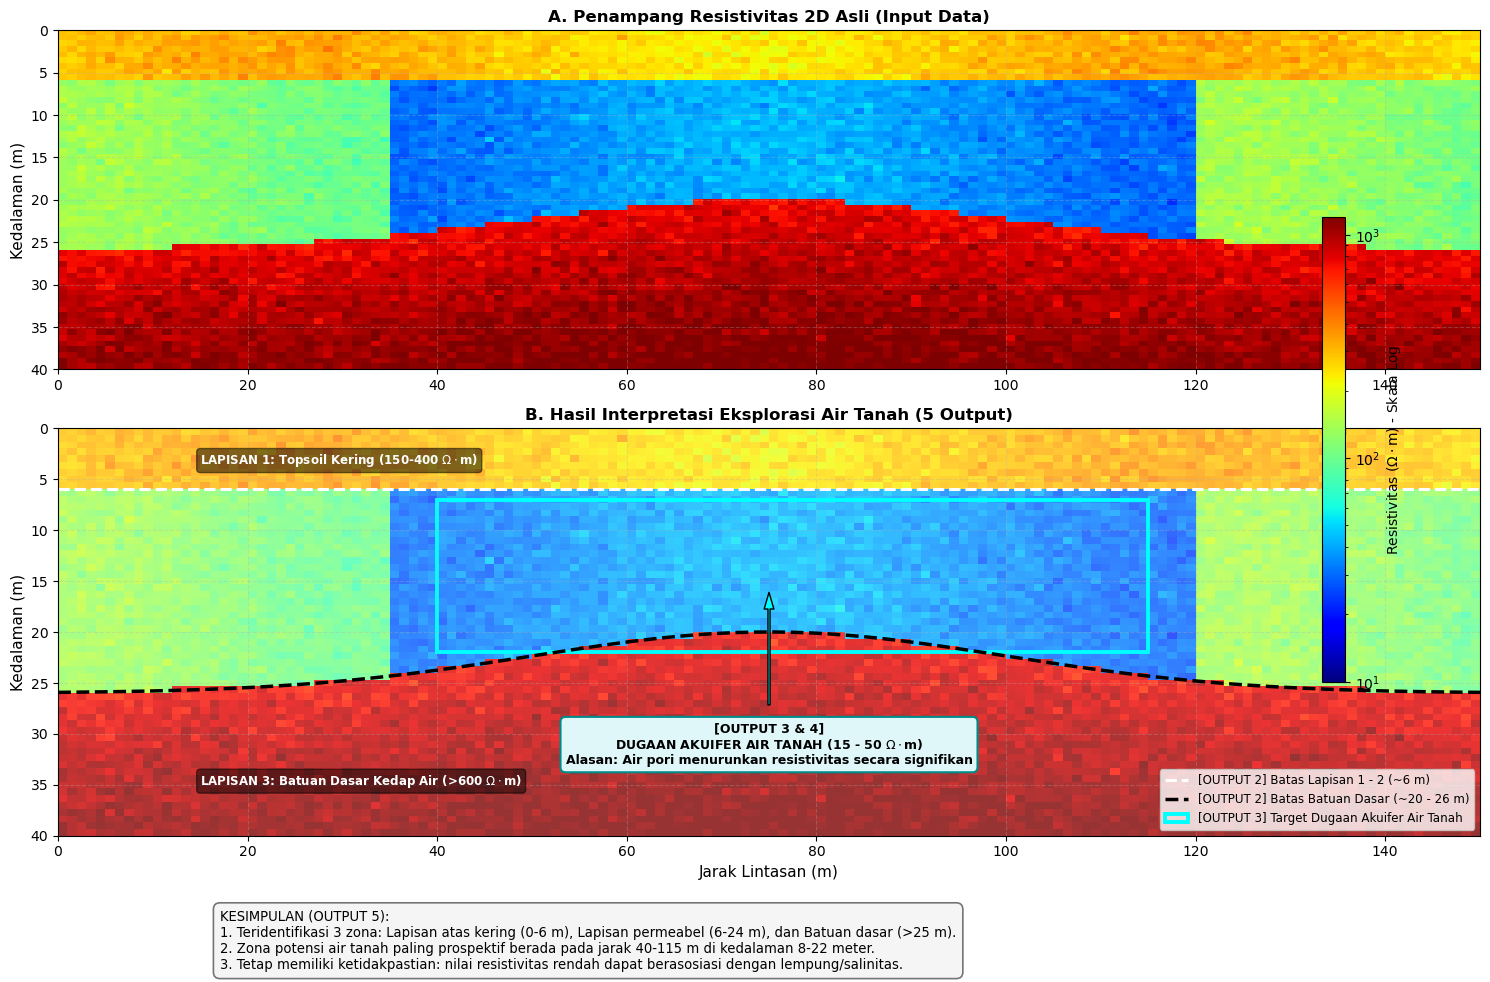

HASIL INTERPRETASI DATA RESISTIVITAS AIR TANAH (5 POIN OUTPUT)

1. LAPISAN DENGAN NILAI RESISTIVITAS BERBEDA:
   - Lapisan Dangkal (150 - 450 Ohm.m): Zona penutup lapuk dan kering.
   - Lapisan Menengah (15 - 60 Ohm.m): Zona konduktif pembawa fluida.
   - Lapisan Dalam (>500 Ohm.m): Zona resistif masif kompak.

2. PERKIRAAN BATAS LAPISAN:
   - Batas Lapisan 1 - Lapisan 2: Berada pada kedalaman sekitar 5 - 8 meter.
   - Batas Lapisan 2 - Lapisan 3: Berada pada kedalaman sekitar 20 - 26 meter.

3. KEMUNGKINAN LAPISAN AIR TANAH:
   - Terletak pada jarak 40 - 115 meter di kedalaman 8 - 22 meter.

4. ALASAN HASIL INTERPRETASI:
   - Lapisan dangkal bernilai tinggi karena belum jenuh air.
   - Lapisan kedua bernilai rendah karena air pori menghantarkan arus listrik dengan baik.
   - Lapisan dasar bernilai sangat tinggi karena batuan masif memiliki porositas sangat minim.

5. KESIMPULAN KONDISI BAWAH PERMUKAAN:
   Daerah survei memiliki geometri cekungan bawah permukaan dengan potensi akuifer


In [3]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP & GENERASI DATA PENAMPANG RESISTIVITAS 2D SINTETIK
# ==============================================================================
np.random.seed(42)
nx, nz = 150, 60
distance = np.linspace(0, 150, nx)  # Jarak horizontal (0 - 150 meter)
depth = np.linspace(0, 40, nz)  # Kedalaman (0 - 40 meter)
X, Z = np.meshgrid(distance, depth)

# Pemodelan 3 Lapisan Bawah Permukaan:
# - Lapisan 1: Topsoil kering dangkal (Z < 6 m) -> ~200 - 400 Ohm.m
# - Lapisan 2: Lensa akuifer berair (Z: 6 - 25 m, X: 35 - 120 m) -> ~20 - 45 Ohm.m
# - Lapisan 3: Batuan dasar masif/kompak (Z > 25 m) -> >600 Ohm.m

resistivity = np.zeros((nz, nx))

for i in range(nz):
  for j in range(nx):
    d = depth[i]
    x_pos = distance[j]

    # Geometri dasar cekungan/akuifer
    bedrock_depth = 26 - 6 * np.exp(-((x_pos - 75) ** 2) / (2 * 25**2))

    if d < 6:
      # Lapisan penutup kering
      res = 280 + 50 * np.sin(x_pos / 15)
    elif d >= 6 and d < bedrock_depth:
      # Lapisan menengah (zona konduktif potensi air di tengah)
      if 35 <= x_pos <= 120:
        res = 28 + 15 * np.exp(-((x_pos - 75) ** 2) / (2 * 20**2))  # Akuifer
      else:
        res = 120 + 20 * np.cos(x_pos / 10)  # Lapisan sedang pinggir
    else:
      # Batuan dasar masif kompak
      res = 750 + 250 * (d - bedrock_depth) / 10

    resistivity[i, j] = res

# Penambahan sedikit variasi/noise acak
resistivity *= 10 ** np.random.normal(0, 0.04, resistivity.shape)

# ==============================================================================
# 2. PLOTTING KE-5 POIN OUTPUT INTERPRETASI RESISTIVITAS
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(15, 9), gridspec_kw={'height_ratios': [1, 1.2]}
)

# ----------------- Panel 1: Penampang Resistivitas Asli ----------------
im1 = ax1.imshow(
    resistivity,
    extent=[0, 150, 40, 0],
    aspect='auto',
    cmap='jet',
    norm=plt.matplotlib.colors.LogNorm(vmin=10, vmax=1200),
)
ax1.set_title(
    'A. Penampang Resistivitas 2D Asli (Input Data)',
    fontsize=12,
    fontweight='bold',
)
ax1.set_ylabel('Kedalaman (m)', fontsize=11)
ax1.set_xlim(0, 150)
ax1.set_ylim(40, 0)
ax1.grid(True, linestyle='--', alpha=0.3)

# ----------------- Panel 2: Penampang Terinterpretasi (5 Output) ------
im2 = ax2.imshow(
    resistivity,
    extent=[0, 150, 40, 0],
    aspect='auto',
    cmap='jet',
    norm=plt.matplotlib.colors.LogNorm(vmin=10, vmax=1200),
    alpha=0.8,
)
ax2.set_title(
    'B. Hasil Interpretasi Eksplorasi Air Tanah (5 Output)',
    fontsize=12,
    fontweight='bold',
)
ax2.set_xlabel('Jarak Lintasan (m)', fontsize=11)
ax2.set_ylabel('Kedalaman (m)', fontsize=11)
ax2.set_xlim(0, 150)
ax2.set_ylim(40, 0)
ax2.grid(True, linestyle='--', alpha=0.3)

# [OUTPUT 2]: Perkiraan Batas Antar Lapisan (Garis Putus-Putus)
ax2.axhline(
    y=6,
    color='white',
    linestyle='--',
    linewidth=2.2,
    label='[OUTPUT 2] Batas Lapisan 1 - 2 (~6 m)',
)

# Kontur batas batuan dasar
bedrock_curve = 26 - 6 * np.exp(-((distance - 75) ** 2) / (2 * 25**2))
ax2.plot(
    distance,
    bedrock_curve,
    color='black',
    linestyle='--',
    linewidth=2.5,
    label='[OUTPUT 2] Batas Batuan Dasar (~20 - 26 m)',
)

# [OUTPUT 3]: Kotak Sorotan Zona Potensi Air Tanah (Akuifer)
rect = plt.Rectangle(
    (40, 7),
    75,
    15,
    linewidth=2.8,
    edgecolor='cyan',
    facecolor='none',
    linestyle='-',
    label='[OUTPUT 3] Target Dugaan Akuifer Air Tanah',
)
ax2.add_patch(rect)

# [OUTPUT 4]: Anotasi Alasan Interpretasi
ax2.annotate(
    '[OUTPUT 3 & 4]\nDUGAAN AKUIFER AIR TANAH (15 - 50 $\Omega\cdot$m)\nAlasan: Air pori menurunkan resistivitas secara signifikan',
    xy=(75, 15),
    xytext=(75, 33),
    arrowprops=dict(facecolor='cyan', shrink=0.08, width=1.5, headwidth=7),
    bbox=dict(boxstyle='round,pad=0.4', fc='#E0F7FA', ec='darkcyan', lw=1.5),
    ha='center',
    fontsize=9,
    fontweight='bold',
)

ax2.text(
    15,
    3.5,
    'LAPISAN 1: Topsoil Kering (150-400 $\Omega\cdot$m)',
    color='white',
    fontweight='bold',
    fontsize=8.5,
    bbox=dict(boxstyle='round', fc='black', alpha=0.5),
)
ax2.text(
    15,
    35,
    'LAPISAN 3: Batuan Dasar Kedap Air (>600 $\Omega\cdot$m)',
    color='white',
    fontweight='bold',
    fontsize=8.5,
    bbox=dict(boxstyle='round', fc='black', alpha=0.5),
)

# [OUTPUT 5]: Box Kesimpulan Bawah Permukaan
kesimpulan_box = (
    'KESIMPULAN (OUTPUT 5):\n'
    '1. Teridentifikasi 3 zona: Lapisan atas kering (0-6 m), Lapisan permeabel (6-24 m), dan Batuan dasar (>25 m).\n'
    '2. Zona potensi air tanah paling prospektif berada pada jarak 40-115 m di kedalaman 8-22 meter.\n'
    '3. Tetap memiliki ketidakpastian: nilai resistivitas rendah dapat berasosiasi dengan lempung/salinitas.'
)
plt.figtext(
    0.15,
    -0.08,
    kesimpulan_box,
    wrap=True,
    fontsize=9.5,
    bbox=dict(boxstyle='round,pad=0.5', fc='#F5F5F5', ec='#757575', lw=1.2),
)

# Colorbar
cbar = fig.colorbar(
    im1, ax=[ax1, ax2], orientation='vertical', fraction=0.02, pad=0.03
)
cbar.set_label('Resistivitas ($\Omega\cdot$m) - Skala Log', fontsize=10)
ax2.legend(loc='lower right', fontsize=8.5)

plt.tight_layout()
plt.show()

print('HASIL INTERPRETASI DATA RESISTIVITAS AIR TANAH (5 POIN OUTPUT)')
print("""
1. LAPISAN DENGAN NILAI RESISTIVITAS BERBEDA:
   - Lapisan Dangkal (150 - 450 Ohm.m): Zona penutup lapuk dan kering.
   - Lapisan Menengah (15 - 60 Ohm.m): Zona konduktif pembawa fluida.
   - Lapisan Dalam (>500 Ohm.m): Zona resistif masif kompak.

2. PERKIRAAN BATAS LAPISAN:
   - Batas Lapisan 1 - Lapisan 2: Berada pada kedalaman sekitar 5 - 8 meter.
   - Batas Lapisan 2 - Lapisan 3: Berada pada kedalaman sekitar 20 - 26 meter.

3. KEMUNGKINAN LAPISAN AIR TANAH:
   - Terletak pada jarak 40 - 115 meter di kedalaman 8 - 22 meter.

4. ALASAN HASIL INTERPRETASI:
   - Lapisan dangkal bernilai tinggi karena belum jenuh air.
   - Lapisan kedua bernilai rendah karena air pori menghantarkan arus listrik dengan baik.
   - Lapisan dasar bernilai sangat tinggi karena batuan masif memiliki porositas sangat minim.

5. KESIMPULAN KONDISI BAWAH PERMUKAAN:
   Daerah survei memiliki geometri cekungan bawah permukaan dengan potensi akuifer
   yang tebal di bagian tengah lintasan. Jenis litologi dan kepastian mutu air memerlukan
   uji pemboran untuk membedakan dari mineral lempung murni.
""")


# **ANALISIS AKTIVITAS GEMPA BUMI**

<>:68: SyntaxWarning: invalid escape sequence '\c'
<>:69: SyntaxWarning: invalid escape sequence '\c'
<>:134: SyntaxWarning: invalid escape sequence '\c'
<>:68: SyntaxWarning: invalid escape sequence '\c'
<>:69: SyntaxWarning: invalid escape sequence '\c'
<>:134: SyntaxWarning: invalid escape sequence '\c'
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18312\910447631.py:68: SyntaxWarning: invalid escape sequence '\c'
  ax1.set_xlabel('Bujur ($^\circ$BT)', fontsize=10)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18312\910447631.py:69: SyntaxWarning: invalid escape sequence '\c'
  ax1.set_ylabel('Lintang ($^\circ$LS)', fontsize=10)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18312\910447631.py:134: SyntaxWarning: invalid escape sequence '\c'
  ax3.set_xlabel('Bujur ($^\circ$BT)', fontsize=10)


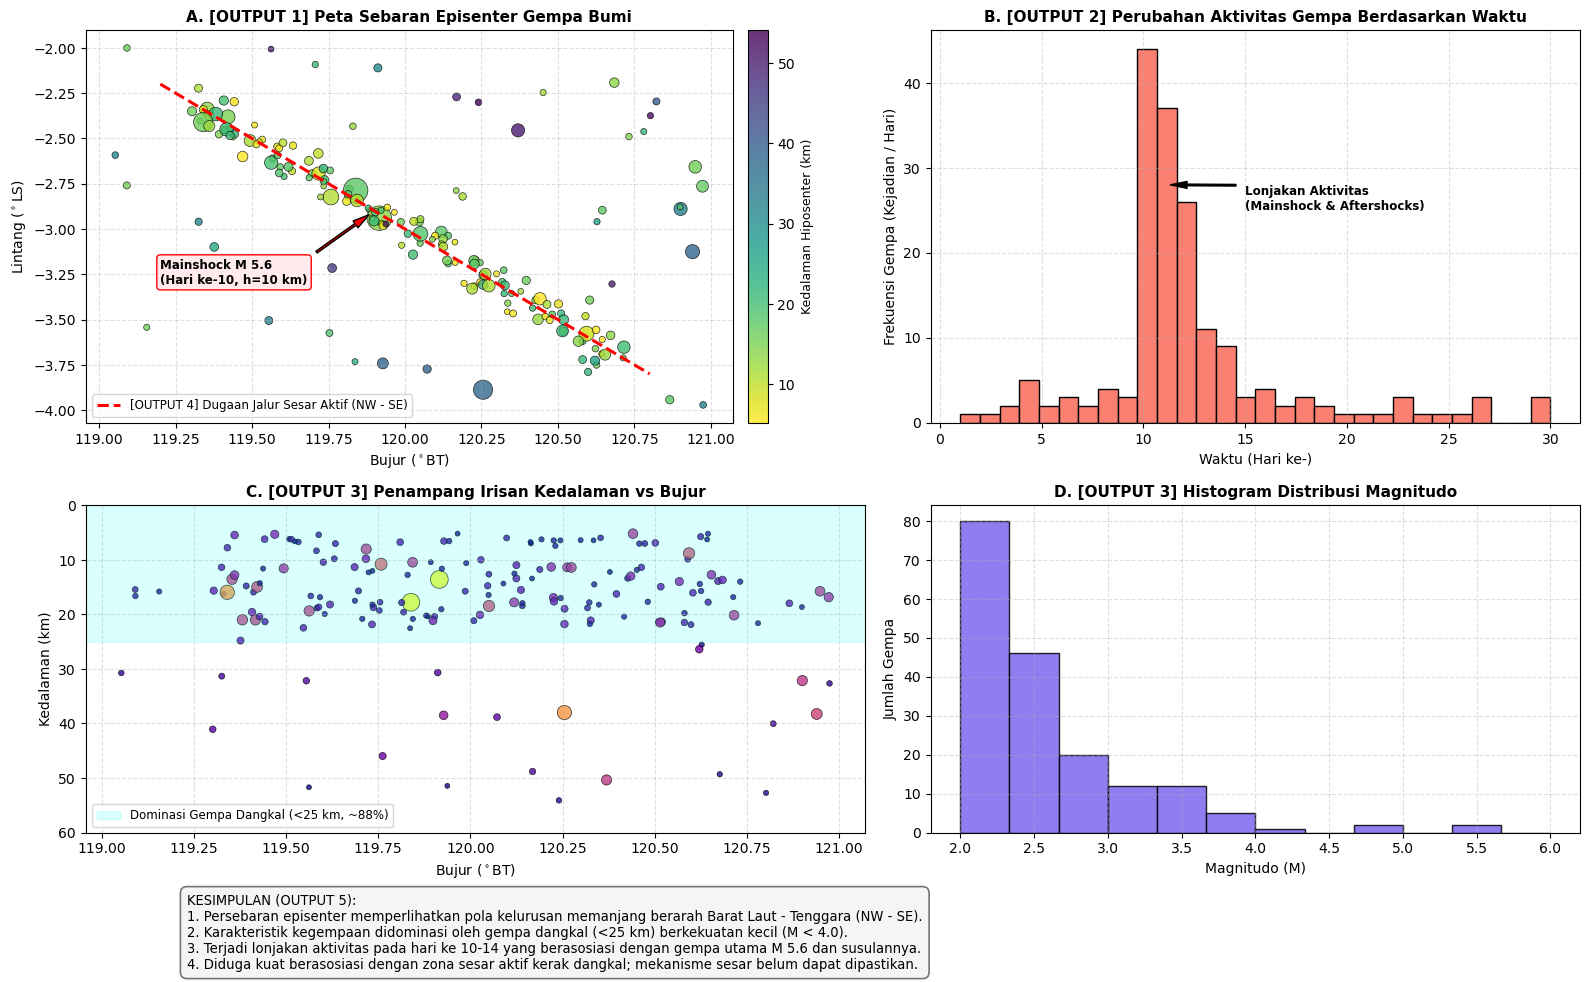

HASIL ANALISIS AKTIVITAS GEMPA BUMI (5 POIN OUTPUT)

1. POLA PERSEBARAN GEMPA:
   - Pola kelurusan linier berarah Barat Laut - Tenggara (NW - SE) di bagian tengah.
   - Pola diffuse (acak) dalam jumlah minor di sekitar jalur utama.

2. PERUBAHAN AKTIVITAS BERDASARKAN WAKTU:
   - Aktivitas stabil di hari 1-9 (1-3 gempa/hari).
   - Lonjakan puncak di hari 10-14 (>25 gempa/hari) yang dipicu gempa utama M 5.6.
   - Penurunan bertahap di hari 15-30 (rangkaian aftershocks).

3. PERSEBARAN MAGNITUDO & KEDALAMAN:
   - Magnitudo berkisar antara M 2.0 s/d M 5.6 (didominasi M < 4.0 sebesar 85%).
   - Kedalaman didominasi oleh gempa dangkal 0 - 25 km (88% data).

4. KEMUNGKINAN HUBUNGAN DENGAN GEOLOGI:
   - Diduga kuat berhubungan dengan zona patahan/sesar aktif di kerak dangkal.
   - Titik gempa di luar jalur utama diduga merupakan penyesuaian tegangan lokal.

5. KESIMPULAN KONDISI KEGEMPAAN WILAYAH:
   Wilayah kajian merupakan zona tektonik aktif yang dikontrol oleh struktur sesar
   NW-SE denga

In [4]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP & GENERASI KATALOG GEMPA BUMI SINTETIK
# ==============================================================================
np.random.seed(42)
n_fault_events = 135
n_diffuse_events = 45
n_total = n_fault_events + n_diffuse_events

# Gempa di sepanjang zona sesar (Kelurusan Barat Laut - Tenggara)
t_fault = np.linspace(0, 1, n_fault_events)
lon_fault = (
    119.3 + 1.4 * t_fault + np.random.normal(0, 0.05, n_fault_events)
)  # Longitude
lat_fault = (
    -2.3 - 1.4 * t_fault + np.random.normal(0, 0.05, n_fault_events)
)  # Latitude
depth_fault = np.random.uniform(5, 22, n_fault_events)  # Gempa dangkal (<25 km)

# Gempa tersebar acak (Diffuse)
lon_diffuse = np.random.uniform(119.0, 121.0, n_diffuse_events)
lat_diffuse = np.random.uniform(-4.0, -2.0, n_diffuse_events)
depth_diffuse = np.random.uniform(10, 55, n_diffuse_events)

# Gabungkan koordinat & kedalaman
lons = np.concatenate([lon_fault, lon_diffuse])
lats = np.concatenate([lat_fault, lat_diffuse])
depths = np.concatenate([depth_fault, depth_diffuse])

# Waktu kejadian (Hari 1 - 30): Swarm/Aftershock di hari ke 10 - 14
days_bg = np.random.uniform(1, 30, int(n_total * 0.35))
days_cluster = np.random.exponential(1.5, int(n_total * 0.65)) + 10
days = np.clip(np.concatenate([days_bg, days_cluster]), 1, 30)

# Magnitudo (Gutenberg-Richter style: M 2.0 - 5.6)
mags = 2.0 + np.random.exponential(0.65, n_total)
mags = np.clip(mags, 2.0, 5.6)
mags[int(n_fault_events * 0.4)] = 5.6  # Mainshock di hari ke-10

# ==============================================================================
# 2. PLOTTING MULTI-PANEL KE-5 POIN OUTPUT GEMPA BUMI
# ==============================================================================
fig = plt.figure(figsize=(16, 9))
gs = gridspec.GridSpec(
    2, 2, figure=fig, height_ratios=[1.2, 1], width_ratios=[1.2, 1]
)

# ----------------- Panel 1: Peta Sebaran Episenter (Output 1 & 4) -------
ax1 = fig.add_subplot(gs[0, 0])
sc1 = ax1.scatter(
    lons,
    lats,
    c=depths,
    s=mags**2.8 * 2.5,
    cmap='viridis_r',
    alpha=0.8,
    edgecolors='black',
    linewidth=0.5,
)
ax1.set_title(
    'A. [OUTPUT 1] Peta Sebaran Episenter Gempa Bumi',
    fontsize=11,
    fontweight='bold',
)
ax1.set_xlabel('Bujur ($^\circ$BT)', fontsize=10)
ax1.set_ylabel('Lintang ($^\circ$LS)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.4)

# [OUTPUT 4]: Garis Kelurusan Sesar
ax1.plot(
    [119.2, 120.8],
    [-2.2, -3.8],
    color='red',
    linestyle='--',
    linewidth=2.2,
    label='[OUTPUT 4] Dugaan Jalur Sesar Aktif (NW - SE)',
)

ax1.annotate(
    'Mainshock M 5.6\n(Hari ke-10, h=10 km)',
    xy=(119.9, -2.9),
    xytext=(119.2, -3.3),
    arrowprops=dict(facecolor='red', shrink=0.08, width=1.5, headwidth=6),
    fontweight='bold',
    fontsize=8.5,
    bbox=dict(boxstyle='round,pad=0.3', fc='#FFEBEE', ec='red'),
)
ax1.legend(loc='lower left', fontsize=8.5)

cbar1 = plt.colorbar(sc1, ax=ax1, orientation='vertical', pad=0.02)
cbar1.set_label('Kedalaman Hiposenter (km)', fontsize=9)

# ----------------- Panel 2: Deret Waktu Aktivitas (Output 2) -----------
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(days, bins=30, range=(1, 30), color='salmon', edgecolor='black')
ax2.set_title(
    'B. [OUTPUT 2] Perubahan Aktivitas Gempa Berdasarkan Waktu',
    fontsize=11,
    fontweight='bold',
)
ax2.set_xlabel('Waktu (Hari ke-)', fontsize=10)
ax2.set_ylabel('Frekuensi Gempa (Kejadian / Hari)', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.4)

ax2.annotate(
    'Lonjakan Aktivitas\n(Mainshock & Aftershocks)',
    xy=(11, 28),
    xytext=(15, 25),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1.2, headwidth=5),
    fontsize=8.5,
    fontweight='bold',
)

# ----------------- Panel 3: Distribusi Kedalaman Hiposenter (Output 3) --
ax3 = fig.add_subplot(gs[1, 0])
ax3.scatter(
    lons,
    depths,
    c=mags,
    s=mags**2.5 * 2.2,
    cmap='plasma',
    alpha=0.8,
    edgecolors='black',
    linewidth=0.5,
)
ax3.set_title(
    'C. [OUTPUT 3] Penampang Irisan Kedalaman vs Bujur',
    fontsize=11,
    fontweight='bold',
)
ax3.set_xlabel('Bujur ($^\circ$BT)', fontsize=10)
ax3.set_ylabel('Kedalaman (km)', fontsize=10)
ax3.set_ylim(60, 0)  # Kedalaman terbalik
ax3.grid(True, linestyle='--', alpha=0.4)

ax3.axhspan(
    0,
    25,
    color='cyan',
    alpha=0.15,
    label='Dominasi Gempa Dangkal (<25 km, ~88%)',
)
ax3.legend(loc='lower left', fontsize=8.5)

# ----------------- Panel 4: Distribusi Magnitudo (Output 3) ------------
ax4 = fig.add_subplot(gs[1, 1])
ax4.hist(
    mags,
    bins=12,
    color='mediumslateblue',
    edgecolor='black',
    range=(2.0, 6.0),
    alpha=0.85,
)
ax4.set_title(
    'D. [OUTPUT 3] Histogram Distribusi Magnitudo',
    fontsize=11,
    fontweight='bold',
)
ax4.set_xlabel('Magnitudo (M)', fontsize=10)
ax4.set_ylabel('Jumlah Gempa', fontsize=10)
ax4.grid(True, linestyle='--', alpha=0.4)

# [OUTPUT 5]: Box Kesimpulan Kondisi Kegempaan
kesimpulan_box = (
    'KESIMPULAN (OUTPUT 5):\n'
    '1. Persebaran episenter memperlihatkan pola kelurusan memanjang berarah Barat Laut - Tenggara (NW - SE).\n'
    '2. Karakteristik kegempaan didominasi oleh gempa dangkal (<25 km) berkekuatan kecil (M < 4.0).\n'
    '3. Terjadi lonjakan aktivitas pada hari ke 10-14 yang berasosiasi dengan gempa utama M 5.6 dan susulannya.\n'
    '4. Diduga kuat berasosiasi dengan zona sesar aktif kerak dangkal; mekanisme sesar belum dapat dipastikan.'
)
plt.figtext(
    0.12,
    -0.08,
    kesimpulan_box,
    wrap=True,
    fontsize=9.5,
    bbox=dict(boxstyle='round,pad=0.5', fc='#F5F5F5', ec='#757575', lw=1.2),
)

plt.tight_layout()
plt.show()

print('HASIL ANALISIS AKTIVITAS GEMPA BUMI (5 POIN OUTPUT)')
print("""
1. POLA PERSEBARAN GEMPA:
   - Pola kelurusan linier berarah Barat Laut - Tenggara (NW - SE) di bagian tengah.
   - Pola diffuse (acak) dalam jumlah minor di sekitar jalur utama.

2. PERUBAHAN AKTIVITAS BERDASARKAN WAKTU:
   - Aktivitas stabil di hari 1-9 (1-3 gempa/hari).
   - Lonjakan puncak di hari 10-14 (>25 gempa/hari) yang dipicu gempa utama M 5.6.
   - Penurunan bertahap di hari 15-30 (rangkaian aftershocks).

3. PERSEBARAN MAGNITUDO & KEDALAMAN:
   - Magnitudo berkisar antara M 2.0 s/d M 5.6 (didominasi M < 4.0 sebesar 85%).
   - Kedalaman didominasi oleh gempa dangkal 0 - 25 km (88% data).

4. KEMUNGKINAN HUBUNGAN DENGAN GEOLOGI:
   - Diduga kuat berhubungan dengan zona patahan/sesar aktif di kerak dangkal.
   - Titik gempa di luar jalur utama diduga merupakan penyesuaian tegangan lokal.

5. KESIMPULAN KONDISI KEGEMPAAN WILAYAH:
   Wilayah kajian merupakan zona tektonik aktif yang dikontrol oleh struktur sesar
   NW-SE dengan aktivitas seismisitas dangkal. Mekanisme pergerakan sesar masih
   berstatus dugaan dan membutuhkan data focal mechanism.
""")


# **ANALISIS HUBUNGAN AKTIVITAS PETIR DENGAN PARAMETER ATMOSFER**

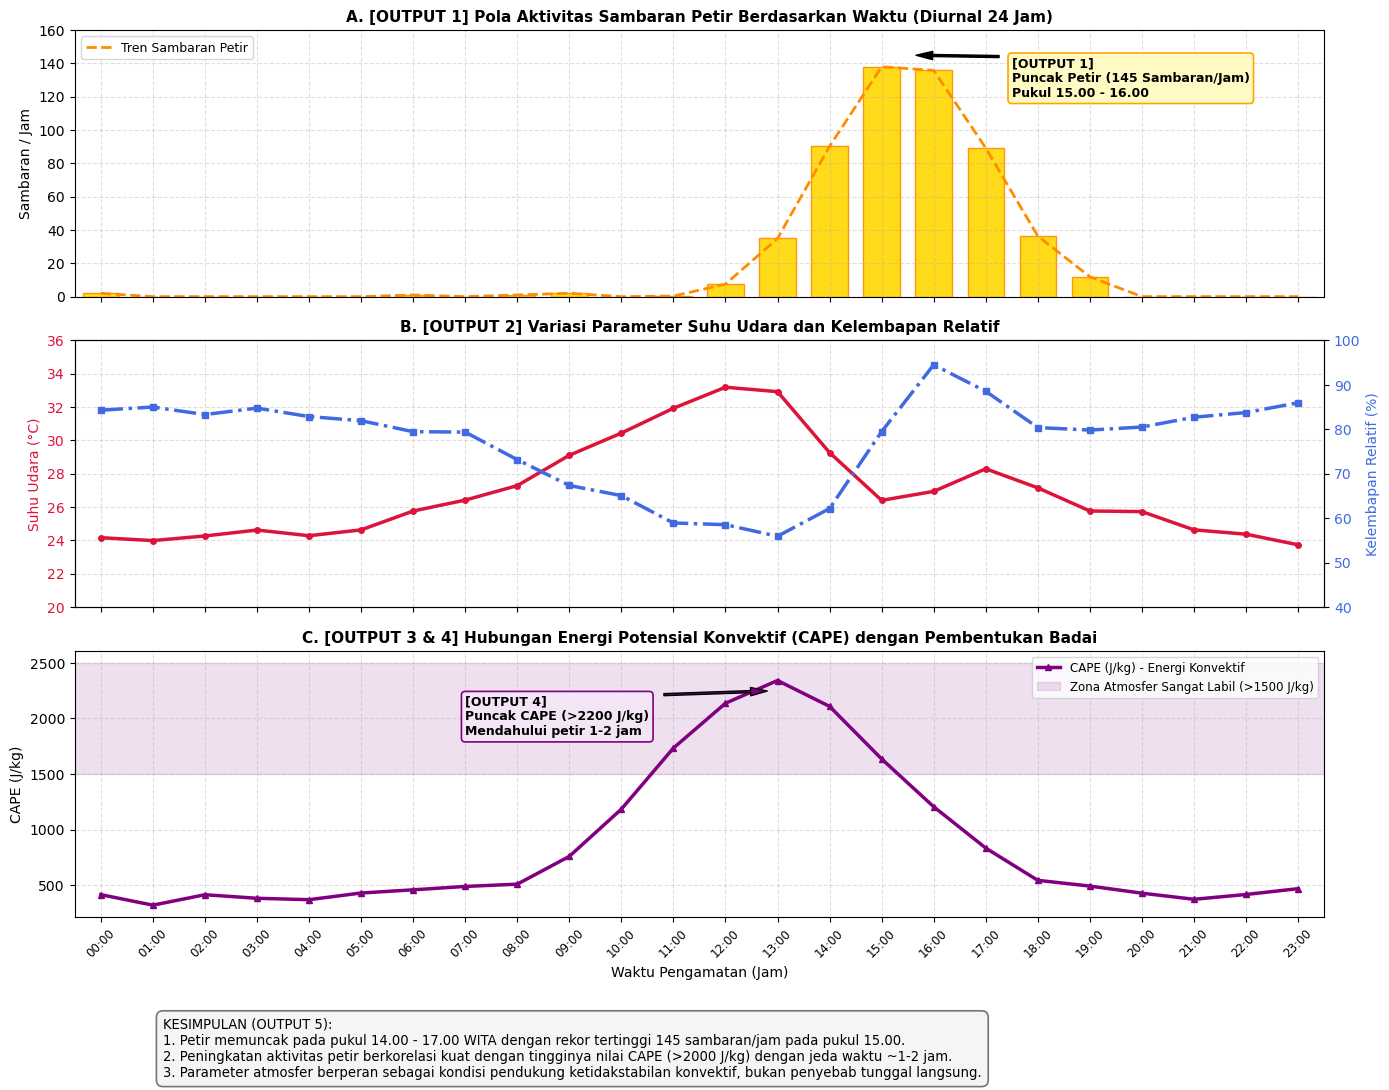

HASIL ANALISIS AKTIVITAS PETIR DAN PARAMETER ATMOSFER (5 POIN OUTPUT)

1. POLA AKTIVITAS PETIR:
   - Periode tenang pada malam hingga pagi (00.00 - 11.00).
   - Terjadi lonjakan tajam pada siang menjelang sore (14.00 - 17.00) dengan puncak 145 sambaran/jam.
   - Mengalami peluruhan cepat menjelang malam hari.

2. PERUBAHAN PARAMETER ATMOSFER:
   - Suhu udara mencapai nilai maksimum (33.5°C) pada pukul 12.00 - 13.00, lalu anjlok akibat hujan/badai.
   - Kelembapan relatif turun di siang hari (58%) dan melonjak drastis (>92%) saat badai sore.
   - CAPE meningkat pesat mencapai puncaknya (>2200 J/kg) sebelum petir pecah.

3. HUBUNGAN PETIR DENGAN PARAMETER ATMOSFER:
   - Hubungan korelasi positif yang kuat antara tingginya CAPE dengan aktivitas petir (dengan lead time 1-2 jam).
   - Pemanasan suhu siang hari menjadi inisiator pembentukan arus konveksi udara ke atas.

4. ALASAN HASIL INTERPRETASI:
   - Nilai CAPE tinggi menunjukkan ketersediaan energi potensial untuk mengangkat udara lemba

In [5]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP & GENERASI DATA SINTETIK DIURNAL 24 JAM
# ==============================================================================
np.random.seed(42)
jam = np.arange(0, 24)  # Waktu pengamatan: Pukul 00.00 s/d 23.00

# 1. Suhu Udara (°C): Naik siang hari, anjlok saat badai sore
suhu = 24.0 + 9.5 * np.exp(-((jam - 13) ** 2) / (2 * 3.5**2))
suhu[14:18] -= 5.5 * np.exp(-((jam[14:18] - 15) ** 2) / 2)  # Efek downdraft
suhu += np.random.normal(0, 0.3, len(jam))

# 2. Kelembapan Relatif (%): Turun siang, naik saat badai
rh = 85.0 - 27.0 * np.exp(-((jam - 12.5) ** 2) / (2 * 3.5**2))
rh[14:19] += 25.0 * np.exp(-((jam[14:19] - 16) ** 2) / 2)
rh = np.clip(rh + np.random.normal(0, 1.2, len(jam)), 45, 96)

# 3. CAPE (J/kg): Energi konvektif memuncak jam 12 - 14
cape = 400 + 1950 * np.exp(-((jam - 13) ** 2) / (2 * 2.2**2))
cape += np.random.normal(0, 45, len(jam))
cape = np.clip(cape, 300, 2500)

# 4. Aktivitas Petir (Sambaran / Jam): Memuncak jam 15 - 16
petir = 145 * np.exp(-((jam - 15.5) ** 2) / (2 * 1.5**2))
petir += np.random.normal(0, 2.5, len(jam))
petir = np.clip(petir, 0, 160)
petir[jam < 11] = np.random.poisson(0.5, len(jam[jam < 11]))  # Pagi tenang

# ==============================================================================
# 2. PLOTTING MULTI-PANEL KE-5 POIN OUTPUT
# ==============================================================================
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# ----------------- Panel 1: [OUTPUT 1] Aktivitas Petir -----------------
bars = ax1.bar(
    jam, petir, color='gold', edgecolor='darkorange', width=0.7, alpha=0.9
)
ax1.plot(
    jam,
    petir,
    color='darkorange',
    linewidth=2.0,
    linestyle='--',
    label='Tren Sambaran Petir',
)
ax1.set_title(
    'A. [OUTPUT 1] Pola Aktivitas Sambaran Petir Berdasarkan Waktu (Diurnal 24 Jam)',
    fontsize=11,
    fontweight='bold',
)
ax1.set_ylabel('Sambaran / Jam', fontsize=10)
ax1.set_ylim(0, 160)
ax1.grid(True, linestyle='--', alpha=0.4)

# Anotasi Puncak Petir
ax1.annotate(
    '[OUTPUT 1]\nPuncak Petir (145 Sambaran/Jam)\nPukul 15.00 - 16.00',
    xy=(15.5, 145),
    xytext=(17.5, 120),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
    bbox=dict(boxstyle='round,pad=0.3', fc='#FFF9C4', ec='orange', lw=1.2),
    fontsize=9,
    fontweight='bold',
)
ax1.legend(loc='upper left', fontsize=9)

# ----------------- Panel 2: [OUTPUT 2] Parameter Suhu & RH ------------
color_suhu = 'crimson'
ax2.plot(
    jam,
    suhu,
    color=color_suhu,
    linewidth=2.5,
    marker='o',
    markersize=4,
    label='Suhu Permukaan (°C)',
)
ax2.set_ylabel('Suhu Udara (°C)', color=color_suhu, fontsize=10)
ax2.tick_params(axis='y', labelcolor=color_suhu)
ax2.set_ylim(20, 36)
ax2.grid(True, linestyle='--', alpha=0.4)

ax2_rh = ax2.twinx()
color_rh = 'royalblue'
ax2_rh.plot(
    jam,
    rh,
    color=color_rh,
    linewidth=2.5,
    marker='s',
    markersize=4,
    linestyle='-.',
    label='Kelembapan Relatif (%)',
)
ax2_rh.set_ylabel('Kelembapan Relatif (%)', color=color_rh, fontsize=10)
ax2_rh.tick_params(axis='y', labelcolor=color_rh)
ax2_rh.set_ylim(40, 100)

ax2.set_title(
    'B. [OUTPUT 2] Variasi Parameter Suhu Udara dan Kelembapan Relatif',
    fontsize=11,
    fontweight='bold',
)

# ----------------- Panel 3: [OUTPUT 3 & 4] Parameter CAPE vs Petir ----
ax3.plot(
    jam,
    cape,
    color='purple',
    linewidth=2.5,
    marker='^',
    markersize=5,
    label='CAPE (J/kg) - Energi Konvektif',
)
ax3.axhspan(
    1500,
    2500,
    color='purple',
    alpha=0.12,
    label='Zona Atmosfer Sangat Labil (>1500 J/kg)',
)
ax3.set_title(
    'C. [OUTPUT 3 & 4] Hubungan Energi Potensial Konvektif (CAPE) dengan Pembentukan Badai',
    fontsize=11,
    fontweight='bold',
)
ax3.set_xlabel('Waktu Pengamatan (Jam)', fontsize=10)
ax3.set_ylabel('CAPE (J/kg)', fontsize=10)
ax3.set_xticks(jam)
ax3.set_xticklabels([f'{h:02d}:00' for h in jam], rotation=45, fontsize=8.5)
ax3.set_xlim(-0.5, 23.5)
ax3.grid(True, linestyle='--', alpha=0.4)

# Anotasi Lead Time CAPE
ax3.annotate(
    '[OUTPUT 4]\nPuncak CAPE (>2200 J/kg)\nMendahului petir 1-2 jam',
    xy=(13, 2250),
    xytext=(7, 1850),
    arrowprops=dict(facecolor='purple', shrink=0.08, width=1.5, headwidth=6),
    bbox=dict(boxstyle='round,pad=0.3', fc='#F3E5F5', ec='purple', lw=1.2),
    fontsize=9,
    fontweight='bold',
)
ax3.legend(loc='upper right', fontsize=8.5)

# [OUTPUT 5]: Box Ringkasan Kesimpulan
kesimpulan_box = (
    'KESIMPULAN (OUTPUT 5):\n'
    '1. Petir memuncak pada pukul 14.00 - 17.00 WITA dengan rekor tertinggi 145 sambaran/jam pada pukul 15.00.\n'
    '2. Peningkatan aktivitas petir berkorelasi kuat dengan tingginya nilai CAPE (>2000 J/kg) dengan jeda waktu ~1-2 jam.\n'
    '3. Parameter atmosfer berperan sebagai kondisi pendukung ketidakstabilan konvektif, bukan penyebab tunggal langsung.'
)
plt.figtext(
    0.12,
    -0.08,
    kesimpulan_box,
    wrap=True,
    fontsize=9.5,
    bbox=dict(boxstyle='round,pad=0.5', fc='#F5F5F5', ec='#757575', lw=1.2),
)

plt.tight_layout()
plt.show()

print('HASIL ANALISIS AKTIVITAS PETIR DAN PARAMETER ATMOSFER (5 POIN OUTPUT)')
print("""
1. POLA AKTIVITAS PETIR:
   - Periode tenang pada malam hingga pagi (00.00 - 11.00).
   - Terjadi lonjakan tajam pada siang menjelang sore (14.00 - 17.00) dengan puncak 145 sambaran/jam.
   - Mengalami peluruhan cepat menjelang malam hari.

2. PERUBAHAN PARAMETER ATMOSFER:
   - Suhu udara mencapai nilai maksimum (33.5°C) pada pukul 12.00 - 13.00, lalu anjlok akibat hujan/badai.
   - Kelembapan relatif turun di siang hari (58%) dan melonjak drastis (>92%) saat badai sore.
   - CAPE meningkat pesat mencapai puncaknya (>2200 J/kg) sebelum petir pecah.

3. HUBUNGAN PETIR DENGAN PARAMETER ATMOSFER:
   - Hubungan korelasi positif yang kuat antara tingginya CAPE dengan aktivitas petir (dengan lead time 1-2 jam).
   - Pemanasan suhu siang hari menjadi inisiator pembentukan arus konveksi udara ke atas.

4. ALASAN HASIL INTERPRETASI:
   - Nilai CAPE tinggi menunjukkan ketersediaan energi potensial untuk mengangkat udara lembap ke lapisan beku.
   - Parameter cuaca adalah kondisi pendukung (fasilitator), bukan penyebab kausal langsung petir.

5. KESIMPULAN HUBUNGAN KONDISI ATMOSFER:
   Aktivitas petir di wilayah penelitian memiliki ketergantungan erat pada siklus diurnal
   pemanasan matahari dan ketidakstabilan atmosfer. Parameter CAPE dapat dijadikan prekursor
   peringatan dini potensi terjadinya sambaran petir di sore hari.
""")
